In [1]:
import pandas as pd
from pathlib import Path

print("Libraries loaded successfully.")

Libraries loaded successfully.


In [2]:
project_root = Path.cwd().parent

raw_file = project_root / "data" / "raw" / "Deblocar_Suivi_Leads_Officiel.xlsx"

print(raw_file)
print("File exists:", raw_file.exists())

c:\Users\chamm\Downloads\deblocar-customer-growth-analytics\data\raw\Deblocar_Suivi_Leads_Officiel.xlsx
File exists: True


In [3]:
excel_file = pd.ExcelFile(raw_file)

print("Number of sheets:", len(excel_file.sheet_names))
print("\nSheets:")
for sheet in excel_file.sheet_names:
    print("-", sheet)

Number of sheets: 16

Sheets:
- 🏠 Accueil
- Feuille 1
- _Listes
- 📊 Dashboard
- 📅 Janvier
- 📅 Février
- 📅 Mars
- 📅 Avril
- 📅 Mai
- 📅 Juin
- 📅 Juillet
- 📅 Août
- 📅 Septembre
- 📅 Octobre
- 📅 Novembre
- 📅 Décembre


In [4]:
monthly_sheets = [
    "📅 Janvier", "📅 Février", "📅 Mars", "📅 Avril",
    "📅 Mai", "📅 Juin", "📅 Juillet", "📅 Août",
    "📅 Septembre", "📅 Octobre", "📅 Novembre", "📅 Décembre"
]

for sheet in monthly_sheets:
    preview = pd.read_excel(
        raw_file,
        sheet_name=sheet,
        header=None
    )

    # Keep rows containing at least one non-empty cell
    non_empty = preview.dropna(how="all")

    print(f"\n{'=' * 50}")
    print(f"{sheet}")
    print("Non-empty rows:", len(non_empty))
    print(non_empty.head(8).to_string(index=False, header=False))


📅 Janvier
Non-empty rows: 4
                                                                                                              DEBLOCAR — Suivi leads  |  Janvier              NaN                  NaN          NaN              NaN             NaN              NaN             NaN             NaN      NaN    NaN          NaN   NaN
                                                                                                                                    Nouveau lead Appel 1 effectué En attente VIN/Photo Vérification Appel 2 effectué    RDV confirmé       RDV honoré    Non faisable          Annulé      NaN    NaN          NaN   NaN
                                                                                                                                             Nom        Téléphone       Source du lead  Gouvernorat  Modèle véhicule Service demandé N° Châssis (VIN) Modèle de poste Code Activation Date RDV Statut Confirm. J-1 Notes
💡 BMW/Mercedes → N° Châssis (VIN

In [5]:
monthly_counts = []

for sheet in monthly_sheets:
    raw = pd.read_excel(raw_file, sheet_name=sheet, header=None)

    # Find the row containing "Nom"
    header_mask = raw.apply(
        lambda row: row.astype(str).str.strip().eq("Nom").any(),
        axis=1
    )

    header_rows = raw.index[header_mask].tolist()

    if not header_rows:
        print(f"⚠️ Header not found: {sheet}")
        continue

    header_idx = header_rows[0]

    # Get headers
    headers = raw.iloc[header_idx].tolist()

    # Remove completely empty header columns
    valid_columns = [
        i for i, col in enumerate(headers)
        if pd.notna(col) and str(col).strip() != ""
    ]

    headers = [headers[i] for i in valid_columns]

    # Data starts two rows after header
    data = raw.iloc[header_idx + 2:, valid_columns].copy()
    data.columns = headers

    # Remove completely empty rows
    data = data.dropna(how="all")

    # Keep rows containing at least one lead field
    lead_columns = [
        col for col in headers
        if col in data.columns
    ]

    data = data.dropna(subset=lead_columns, how="all")

    monthly_counts.append({
        "Month": sheet,
        "Lead rows": len(data)
    })

counts_df = pd.DataFrame(monthly_counts)

display(counts_df)

print("Total lead rows:", counts_df["Lead rows"].sum())

,Month,Lead rows
0,📅 Janvier,1
1,📅 Février,1
2,📅 Mars,1
3,📅 Avril,1
4,📅 Mai,1
5,📅 Juin,54
6,📅 Juillet,76
7,📅 Août,29
8,📅 Septembre,7
9,📅 Octobre,1


Total lead rows: 174


In [6]:
june_raw = pd.read_excel(
    raw_file,
    sheet_name="📅 Juin",
    header=None
)

header_idx = june_raw.index[
    june_raw.apply(
        lambda row: row.astype(str).str.strip().eq("Nom").any(),
        axis=1
    )
][0]

june_headers = june_raw.iloc[header_idx].tolist()

june_df = june_raw.iloc[header_idx + 2:].copy()
june_df.columns = june_headers
june_df = june_df.dropna(how="all")

display(june_df.head(10))
print("June rows:", len(june_df))
print("Columns:", june_df.columns.tolist())

,Nom,Téléphone,Source du lead,Gouvernorat,Modèle véhicule,Service demandé,N° Châssis (VIN),Modèle de poste,Code Activation,Date RDV,Statut,Confirm. J-1,Notes,NaN
4,Yacine Fendri,NaN,Messenger,NaN,Mercedes CLA,Fonctions cachées,W1K1183841N342780\n,NaN,NaN,NaN,Nouveau lead,NaN,NaN,NaN
5,Salwen Mahmoud,NaN,Instagram,NaN,VW Golf 7.5,Apple CarPlay,NaN,MST2_EU_VW_ZR_P0475T,NaN,NaN,Nouveau lead,NaN,NaN,NaN
6,Hamza Guenenna,NaN,Instagram,NaN,SEAT leon,Fonctions cachées,NaN,5F0035824C,NaN,NaN,Nouveau lead,NaN,Il a contacté Yahya directement sur WhatsApp,NaN
7,Mohamed Ben Rejeb,NaN,Messenger,NaN,Mercedes Classe C,Activation alarme,WDD2040491A363800,NaN,NaN,NaN,Nouveau lead,NaN,NaN,NaN
8,Amir Charfi,NaN,Messenger,NaN,Mercedes GLC,Fonctions cachées,W1NK.J5GBXSF357169,NaN,NaN,NaN,Nouveau lead,NaN,NaN,NaN
9,Hamza BD,NaN,Instagram,NaN,Audi Q3,Fonctions cachées,NaN,NaN,NaN,NaN,En attente VIN/Photo,NaN,NaN,NaN
10,Youssef Gomri,NaN,Instagram,NaN,Audi Q5,Navigation + Apple CarPlay,NaN,NaN,NaN,NaN,En attente VIN/Photo,NaN,lbluetooth yekhdem ken des appels téléphonique...,NaN
11,Mohamed Zaier,NaN,Messenger,NaN,Ibiza,Fonctions cachées,NaN,NaN,NaN,NaN,Nouveau lead,NaN,Il a contacté l'équipe directement sur WhatsApp,NaN
12,Ayoub Lassoued,NaN,Messenger,Tunis,BMW X3,Navigation GPS,5UXTY5C09M9H51406,NaN,NaN,NaN,Nouveau lead,NaN,Il a contacté l'équipe directement sur WhatsApp,NaN
13,Nidhal Trabelsi,NaN,Messenger,Sousse,Nissan,Fonctions cachées,NaN,NaN,NaN,NaN,Non faisable,NaN,NaN,NaN


June rows: 54
Columns: ['Nom', 'Téléphone', 'Source du lead', 'Gouvernorat', 'Modèle véhicule', 'Service demandé', 'N° Châssis (VIN)', 'Modèle de poste', 'Code Activation', 'Date RDV', 'Statut', 'Confirm. J-1', 'Notes', nan]


In [7]:
for sheet in monthly_sheets:
    if sheet in ["📅 Juin", "📅 Juillet", "📅 Août", "📅 Septembre"]:
        continue

    raw = pd.read_excel(raw_file, sheet_name=sheet, header=None)

    header_mask = raw.apply(
        lambda row: row.astype(str).str.strip().eq("Nom").any(),
        axis=1
    )

    header_idx = raw.index[header_mask][0]

    print(f"\n--- {sheet} ---")
    display(raw.iloc[header_idx + 1:header_idx + 5])


--- 📅 Janvier ---


,0,1,2,3,4,5,6,7,8,9,10,11,12
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- 📅 Février ---


,0,1,2,3,4,5,6,7,8,9,10,11,12
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- 📅 Mars ---


...

,0,1,2,3,4,5,6,7,8,9,10,11,12
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- 📅 Novembre ---


,0,1,2,3,4,5,6,7,8,9,10,11,12
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN



--- 📅 Décembre ---


,0,1,2,3,4,5,6,7,8,9,10,11,12
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
5,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
6,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:
combined_data = []

active_months = ["📅 Juin", "📅 Juillet", "📅 Août", "📅 Septembre"]

for sheet in active_months:
    raw = pd.read_excel(raw_file, sheet_name=sheet, header=None)

    # Find the header row
    header_mask = raw.apply(
        lambda row: row.astype(str).str.strip().eq("Nom").any(),
        axis=1
    )

    header_idx = raw.index[header_mask][0]

    # Keep only columns with actual headers
    headers = raw.iloc[header_idx].tolist()

    valid_columns = [
        i for i, col in enumerate(headers)
        if pd.notna(col) and str(col).strip() != ""
    ]

    headers = [headers[i] for i in valid_columns]

    # Skip header + guidance row
    data = raw.iloc[header_idx + 2:, valid_columns].copy()
    data.columns = headers

    # Remove completely empty rows
    data = data.dropna(how="all")

    # Add month/source information
    data["Lead Month"] = sheet.replace("📅 ", "")
    data["Source Sheet"] = sheet

    combined_data.append(data)

# Combine all months
combined_df = pd.concat(combined_data, ignore_index=True)

print("Total leads:", len(combined_df))
print("Columns:", list(combined_df.columns))

display(combined_df.head(10))

Total leads: 166
Columns: ['Nom', 'Téléphone', 'Source du lead', 'Gouvernorat', 'Modèle véhicule', 'Service demandé', 'N° Châssis (VIN)', 'Modèle de poste', 'Code Activation', 'Date RDV', 'Statut', 'Confirm. J-1', 'Notes', 'Lead Month', 'Source Sheet']


,Nom,Téléphone,Source du lead,Gouvernorat,Modèle véhicule,Service demandé,N° Châssis (VIN),Modèle de poste,Code Activation,Date RDV,Statut,Confirm. J-1,Notes,Lead Month,Source Sheet
0,Yacine Fendri,NaN,Messenger,NaN,Mercedes CLA,Fonctions cachées,W1K1183841N342780\n,NaN,NaN,NaN,Nouveau lead,NaN,NaN,Juin,📅 Juin
1,Salwen Mahmoud,NaN,Instagram,NaN,VW Golf 7.5,Apple CarPlay,NaN,MST2_EU_VW_ZR_P0475T,NaN,NaN,Nouveau lead,NaN,NaN,Juin,📅 Juin
2,Hamza Guenenna,NaN,Instagram,NaN,SEAT leon,Fonctions cachées,NaN,5F0035824C,NaN,NaN,Nouveau lead,NaN,Il a contacté Yahya directement sur WhatsApp,Juin,📅 Juin
3,Mohamed Ben Rejeb,NaN,Messenger,NaN,Mercedes Classe C,Activation alarme,WDD2040491A363800,NaN,NaN,NaN,Nouveau lead,NaN,NaN,Juin,📅 Juin
4,Amir Charfi,NaN,Messenger,NaN,Mercedes GLC,Fonctions cachées,W1NK.J5GBXSF357169,NaN,NaN,NaN,Nouveau lead,NaN,NaN,Juin,📅 Juin
5,Hamza BD,NaN,Instagram,NaN,Audi Q3,Fonctions cachées,NaN,NaN,NaN,NaN,En attente VIN/Photo,NaN,NaN,Juin,📅 Juin
6,Youssef Gomri,NaN,Instagram,NaN,Audi Q5,Navigation + Apple CarPlay,NaN,NaN,NaN,NaN,En attente VIN/Photo,NaN,lbluetooth yekhdem ken des appels téléphonique...,Juin,📅 Juin
7,Mohamed Zaier,NaN,Messenger,NaN,Ibiza,Fonctions cachées,NaN,NaN,NaN,NaN,Nouveau lead,NaN,Il a contacté l'équipe directement sur WhatsApp,Juin,📅 Juin
8,Ayoub Lassoued,NaN,Messenger,Tunis,BMW X3,Navigation GPS,5UXTY5C09M9H51406,NaN,NaN,NaN,Nouveau lead,NaN,Il a contacté l'équipe directement sur WhatsApp,Juin,📅 Juin
9,Nidhal Trabelsi,NaN,Messenger,Sousse,Nissan,Fonctions cachées,NaN,NaN,NaN,NaN,Non faisable,NaN,NaN,Juin,📅 Juin


In [9]:
from pathlib import Path

interim_file = Path("../data/interim/combined_leads.xlsx")

combined_df.to_excel(interim_file, index=False)

print(f"Saved successfully to: {interim_file}")
print(f"Rows: {len(combined_df)}")
print(f"Columns: {len(combined_df.columns)}")

Saved successfully to: ..\data\interim\combined_leads.xlsx
Rows: 166
Columns: 15


In [10]:
print("Dataset shape:", combined_df.shape)

print("\n--- Columns ---")
print(combined_df.columns.tolist())

print("\n--- Missing values ---")
display(
    combined_df.isna()
    .sum()
    .sort_values(ascending=False)
    .to_frame("Missing values")
)

print("\n--- Status values ---")
display(combined_df["Statut"].value_counts(dropna=False))

print("\n--- Lead sources ---")
display(combined_df["Source du lead"].value_counts(dropna=False))

print("\n--- Services requested ---")
display(combined_df["Service demandé"].value_counts(dropna=False))

Dataset shape: (166, 15)

--- Columns ---
['Nom', 'Téléphone', 'Source du lead', 'Gouvernorat', 'Modèle véhicule', 'Service demandé', 'N° Châssis (VIN)', 'Modèle de poste', 'Code Activation', 'Date RDV', 'Statut', 'Confirm. J-1', 'Notes', 'Lead Month', 'Source Sheet']

--- Missing values ---


,Missing values
Code Activation,166
Confirm. J-1,165
Modèle de poste,157
N° Châssis (VIN),111
Date RDV,105
Notes,66
Téléphone,61
Gouvernorat,52
Nom,31
Service demandé,20



--- Status values ---


Statut
RDV confirmé            54
Nouveau lead            36
Done                    23
En attente VIN/Photo    14
Vérification            11
NaN                     10
Non faisable             6
Annulé                   5
indisponible             2
non-faisable             1
annulé!                  1
Appel 1 effectué         1
annulation               1
RDV honoré               1
Name: count, dtype: int64


--- Lead sources ---


Source du lead
Messenger       58
WhatsApp        51
Instagram       26
NaN             17
Appel direct     7
messenger        5
whatsapp         2
Name: count, dtype: int64


--- Services requested ---


Service demandé
Fonctions cachées                               42
Navigation GPS                                  23
NaN                                             20
Apple CarPlay                                   19
Navigation                                       6
Navigation + Apple CarPlay                       5
Activation alarme                                4
Autre                                            4
Android Auto                                     3
Diagnostique                                     3
Navigation + CarPlay + Alarme                    2
Navigation + Pack AMG                            2
App connect                                      2
Nvigation + Android Auto                         2
Android auto+ navigation                         1
Navigation+ options cachées                      1
CarPlay + Android Auto                           1
Carplay + alarme                                 1
Alarme + navigation                              1
Navigation+ Car

In [11]:
# Create a working copy
clean_df = combined_df.copy()

# Standardize lead sources
source_mapping = {
    "messenger": "Messenger",
    "whatsapp": "WhatsApp",
    "instagram": "Instagram",
    "appel direct": "Appel direct"
}

clean_df["Source du lead"] = (
    clean_df["Source du lead"]
    .astype("string")
    .str.strip()
    .replace(source_mapping)
)

# Standardize obvious status variations
status_mapping = {
    "non-faisable": "Non faisable",
    "annulé!": "Annulé"
}

clean_df["Statut"] = (
    clean_df["Statut"]
    .astype("string")
    .str.strip()
    .replace(status_mapping)
)

# Display updated categories
print("--- Standardized lead sources ---")
display(clean_df["Source du lead"].value_counts(dropna=False))

print("--- Standardized statuses ---")
display(clean_df["Statut"].value_counts(dropna=False))

--- Standardized lead sources ---


Source du lead
Messenger       63
WhatsApp        53
Instagram       26
<NA>            17
Appel direct     7
Name: count, dtype: Int64

--- Standardized statuses ---


Statut
RDV confirmé            54
Nouveau lead            36
Done                    23
En attente VIN/Photo    14
Vérification            11
<NA>                    10
Non faisable             7
Annulé                   6
indisponible             2
Appel 1 effectué         1
annulation               1
RDV honoré               1
Name: count, dtype: Int64

In [12]:
# 1. Exact duplicate rows
exact_duplicates = clean_df.duplicated().sum()

# 2. Duplicate phone numbers (excluding missing values)
phone_values = clean_df["Téléphone"].astype("string").str.strip()
phone_values = phone_values.replace("", pd.NA)

duplicate_phones = phone_values.duplicated(keep=False) & phone_values.notna()

# 3. Duplicate VINs (excluding missing values)
vin_values = clean_df["N° Châssis (VIN)"].astype("string").str.strip()
vin_values = vin_values.replace("", pd.NA)

duplicate_vins = vin_values.duplicated(keep=False) & vin_values.notna()

print("Exact duplicate rows:", exact_duplicates)
print("Rows with repeated phone numbers:", duplicate_phones.sum())
print("Rows with repeated VINs:", duplicate_vins.sum())

print("\nUnique repeated phone numbers:",
      phone_values[duplicate_phones].nunique())

print("Unique repeated VINs:",
      vin_values[duplicate_vins].nunique())

Exact duplicate rows: 0
Rows with repeated phone numbers: 10
Rows with repeated VINs: 4

Unique repeated phone numbers: 5
Unique repeated VINs: 2


In [13]:
# Create a business-level status grouping
status_groups = {
    "Done": "Service completed",
    "RDV honoré": "Appointment attended - completion unverified",
    "RDV confirmé": "Appointment confirmed",
    "Annulé": "Cancelled",
    "annulation": "Cancelled",
    "Non faisable": "Not feasible",
    "Nouveau lead": "In progress",
    "En attente VIN/Photo": "In progress",
    "Vérification": "In progress",
    "Appel 1 effectué": "In progress",
    "indisponible": "Needs review"
}

clean_df["Status Group"] = clean_df["Statut"].map(status_groups)

# Missing or unrecognized statuses remain unclassified
clean_df["Status Group"] = clean_df["Status Group"].fillna(
    "Unclassified"
)

# Summary table
funnel_df = (
    clean_df["Status Group"]
    .value_counts()
    .rename_axis("Status Group")
    .reset_index(name="Lead Count")
)

funnel_df["Percentage"] = (
    funnel_df["Lead Count"] / len(clean_df) * 100
).round(1)

display(funnel_df)

,Status Group,Lead Count,Percentage
0,In progress,62,37.3
1,Appointment confirmed,54,32.5
2,Service completed,23,13.9
3,Unclassified,10,6.0
4,Not feasible,7,4.2
5,Cancelled,7,4.2
6,Needs review,2,1.2
7,Appointment attended - completion unverified,1,0.6


In [14]:
# Calculate key business KPIs
total_leads = len(clean_df)

kpi_data = {
    "Total leads": total_leads,
    "Service completed": (clean_df["Status Group"] == "Service completed").sum(),
    "Appointments confirmed": (clean_df["Status Group"] == "Appointment confirmed").sum(),
    "Leads in progress": (clean_df["Status Group"] == "In progress").sum(),
    "Cancelled leads": (clean_df["Status Group"] == "Cancelled").sum(),
    "Not feasible leads": (clean_df["Status Group"] == "Not feasible").sum(),
    "Unclassified leads": (clean_df["Status Group"] == "Unclassified").sum(),
}

kpi_df = pd.DataFrame(
    list(kpi_data.items()),
    columns=["KPI", "Value"]
)

kpi_df["Share (%)"] = (
    kpi_df["Value"] / total_leads * 100
).round(1)

display(kpi_df)

,KPI,Value,Share (%)
0,Total leads,166,100.0
1,Service completed,23,13.9
2,Appointments confirmed,54,32.5
3,Leads in progress,62,37.3
4,Cancelled leads,7,4.2
5,Not feasible leads,7,4.2
6,Unclassified leads,10,6.0


In [15]:
# 1. Lead source analysis
source_analysis = (
    clean_df["Source du lead"]
    .fillna("Missing")
    .value_counts()
    .rename_axis("Lead Source")
    .reset_index(name="Lead Count")
)

source_analysis["Share (%)"] = (
    source_analysis["Lead Count"] / len(clean_df) * 100
).round(1)

print("--- Lead Sources ---")
display(source_analysis)


# 2. Service demand analysis
service_analysis = (
    clean_df["Service demandé"]
    .fillna("Missing")
    .value_counts()
    .rename_axis("Service")
    .reset_index(name="Lead Count")
)

service_analysis["Share (%)"] = (
    service_analysis["Lead Count"] / len(clean_df) * 100
).round(1)

print("--- Services Requested ---")
display(service_analysis)

--- Lead Sources ---


,Lead Source,Lead Count,Share (%)
0,Messenger,63,38.0
1,WhatsApp,53,31.9
2,Instagram,26,15.7
3,Missing,17,10.2
4,Appel direct,7,4.2


--- Services Requested ---


,Service,Lead Count,Share (%)
0,Fonctions cachées,42,25.3
1,Navigation GPS,23,13.9
2,Missing,20,12.0
3,Apple CarPlay,19,11.4
4,Navigation,6,3.6
5,Navigation + Apple CarPlay,5,3.0
6,Activation alarme,4,2.4
7,Autre,4,2.4
8,Android Auto,3,1.8
9,Diagnostique,3,1.8


In [16]:
# Cross-tabulation: lead source vs. business status
source_status = pd.crosstab(
    clean_df["Source du lead"].fillna("Missing"),
    clean_df["Status Group"]
)

print("--- Lead Source vs. Status Group ---")
display(source_status)

# Calculate completed services by source
completed_by_source = (
    clean_df.assign(
        Completed=clean_df["Status Group"].eq("Service completed")
    )
    .groupby("Source du lead", dropna=False)
    .agg(
        Total_Leads=("Status Group", "size"),
        Completed_Services=("Completed", "sum")
    )
    .reset_index()
)

completed_by_source["Completion Share (%)"] = (
    completed_by_source["Completed_Services"]
    / completed_by_source["Total_Leads"] * 100
).round(1)

display(completed_by_source)

--- Lead Source vs. Status Group ---


Status Group,Appointment attended - completion unverified,Appointment confirmed,Cancelled,In progress,Needs review,Not feasible,Service completed,Unclassified
Source du lead,,,,,,,,
Appel direct,1,4,1,0,0,0,0,1
Instagram,0,3,1,18,0,2,2,0
Messenger,0,16,4,36,1,5,1,0
Missing,0,3,0,4,0,0,1,9
WhatsApp,0,28,1,4,1,0,19,0


,Source du lead,Total_Leads,Completed_Services,Completion Share (%)
0,Appel direct,7,0,0.0
1,Instagram,26,2,7.7
2,Messenger,63,1,1.6
3,WhatsApp,53,19,35.8
4,<NA>,17,1,5.9


In [17]:
# Service requested vs. business status
service_status = pd.crosstab(
    clean_df["Service demandé"].fillna("Missing"),
    clean_df["Status Group"]
)

display(service_status)

# Completed services by requested service
completed_by_service = (
    clean_df.assign(
        Completed=clean_df["Status Group"].eq("Service completed")
    )
    .groupby("Service demandé", dropna=False)
    .agg(
        Total_Leads=("Status Group", "size"),
        Completed_Services=("Completed", "sum")
    )
    .reset_index()
)

completed_by_service["Completion Share (%)"] = (
    completed_by_service["Completed_Services"]
    / completed_by_service["Total_Leads"] * 100
).round(1)

completed_by_service = completed_by_service.sort_values(
    "Total_Leads", ascending=False
)

display(completed_by_service)

Status Group,Appointment attended - completion unverified,Appointment confirmed,Cancelled,In progress,Needs review,Not feasible,Service completed,Unclassified
Service demandé,,,,,,,,
Activation alarme,0,0,1,1,0,0,2,0
Alarme,0,0,0,0,0,0,1,0
Alarme + navigation,0,0,0,1,0,0,0,0
"Alarme, Wireless CarPlay+ Camera recul",0,0,0,0,0,0,1,0
Android Auto,0,1,0,2,0,0,0,0
Android Auto+ Navigation,0,0,0,0,0,0,1,0
Android auto+ navigation,0,0,0,1,0,0,0,0
App connect,0,0,1,1,0,0,0,0
Apple CarPlay,0,2,3,12,0,1,1,0


,Service demandé,Total_Leads,Completed_Services,Completion Share (%)
17,Fonctions cachées,42,6,14.3
28,Navigation GPS,23,3,13.0
42,NaN,20,0,0.0
8,Apple CarPlay,19,1,5.3
21,Navigation,6,1,16.7
22,Navigation + Apple CarPlay,5,0,0.0
9,Autre,4,0,0.0
0,Activation alarme,4,2,50.0
4,Android Auto,3,0,0.0
16,Diagnostique,3,2,66.7


In [18]:
import pandas as pd

# Normalize text for matching
service_text = (
    clean_df["Service demandé"]
    .astype("string")
    .str.strip()
)

# Standardize obvious variations
service_mapping = {
    "Carplay": "Apple CarPlay",
    "CarPlay": "Apple CarPlay",
    "Diagnostic": "Diagnostique",
    "dignostic+alarme": "Diagnostique + Alarme",
    "Nvigation + Android Auto": "Navigation + Android Auto",
    "Android auto+ navigation": "Navigation + Android Auto",
    "navigation + android auto": "Navigation + Android Auto",
    "Android Auto+ Navigation": "Navigation + Android Auto",
    "Navigation+ CarPlay": "Navigation + Apple CarPlay",
    "Navigation + Apple CarPlay": "Navigation + Apple CarPlay",
    "navigation + alarme": "Navigation + Alarme",
}

clean_df["Service Standardized"] = service_text.replace(service_mapping)

print("Original service labels:", service_text.nunique())
print("Standardized service labels:", clean_df["Service Standardized"].nunique())

display(
    clean_df["Service Standardized"]
    .fillna("Missing")
    .value_counts()
    .to_frame("Lead Count")
)

Original service labels: 42
Standardized service labels: 35


,Lead Count
Service Standardized,
Fonctions cachées,42
Navigation GPS,23
Apple CarPlay,21
Missing,20
Navigation,6
Navigation + Apple CarPlay,6
Navigation + Android Auto,5
Activation alarme,4
Autre,4


In [19]:
display(
    clean_df["Service Standardized"]
    .value_counts()
    .loc[lambda x: x == 1]
    .to_frame("Lead Count")
) 

,Lead Count
Service Standardized,
Carplay + alarme,1
Alarme + navigation,1
Full Link,1
gadget + navigateur + alarme,1
Navigation+ options cachées,1
CarPlay + Android Auto,1
GPS,1
Diagnostique + Alarme,1
Navigation + Alarme,1


In [20]:
service_mapping_extra = {
    "Alarme + navigation": "Navigation + Alarme",
    "Navigation+alarme+Rline": "Navigation + Alarme + Rline",
    "Navigation+ options cachées": "Navigation + Options cachées",
    "Navigation+ caméra de récul+ options cachées":
        "Navigation + Caméra de recul + Options cachées",
    "Carplay + alarme": "CarPlay + Alarme",
}

clean_df["Service Standardized"] = (
    clean_df["Service Standardized"].replace(service_mapping_extra)
)

display(
    clean_df["Service Standardized"]
    .fillna("Missing")
    .value_counts()
    .to_frame("Lead Count")
)

,Lead Count
Service Standardized,
Fonctions cachées,42
Navigation GPS,23
Apple CarPlay,21
Missing,20
Navigation + Apple CarPlay,6
Navigation,6
Navigation + Android Auto,5
Activation alarme,4
Autre,4


In [21]:
from pathlib import Path

output_path = Path("../data/processed/leads_clean.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

clean_df.to_csv(output_path, index=False, encoding="utf-8-sig")

print(f"Saved: {output_path}")
print(f"Rows: {len(clean_df)}")
print(f"Columns: {len(clean_df.columns)}")

Saved: ..\data\processed\leads_clean.csv
Rows: 166
Columns: 17


In [22]:
import pandas as pd
from pathlib import Path

anon_df = clean_df.copy()

# Create anonymous lead ID
anon_df.insert(
    0,
    "Lead ID",
    [f"LEAD_{i:03d}" for i in range(1, len(anon_df) + 1)]
)

# Remove direct identifiers and sensitive/free-text fields
columns_to_remove = [
    "Nom",
    "Téléphone",
    "N° Châssis (VIN)",
    "Code Activation",
    "Notes"
]

anon_df = anon_df.drop(
    columns=[col for col in columns_to_remove if col in anon_df.columns]
)

# Save anonymized dataset
output_path = Path("../data/processed/leads_anonymized.csv")
output_path.parent.mkdir(parents=True, exist_ok=True)

anon_df.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"Saved: {output_path}")
print(f"Rows: {len(anon_df)}")
print(f"Columns: {len(anon_df.columns)}")

Saved: ..\data\processed\leads_anonymized.csv
Rows: 166
Columns: 13


In [23]:
# 1. Dataset dimensions
print("Dataset shape:", anon_df.shape)

# 2. Duplicate rows
print("Duplicate rows:", anon_df.duplicated().sum())

# 3. Missing values
missing_values = (
    anon_df.isna()
    .sum()
    .to_frame("Missing Values")
)

missing_values["Missing %"] = (
    missing_values["Missing Values"] / len(anon_df) * 100
).round(2)

display(missing_values[missing_values["Missing Values"] > 0])

# 4. Data types
display(anon_df.dtypes.to_frame("Data Type"))

Dataset shape: (166, 13)
Duplicate rows: 0


,Missing Values,Missing %
Source du lead,17,10.24
Gouvernorat,52,31.33
Modèle véhicule,10,6.02
Service demandé,20,12.05
Modèle de poste,157,94.58
Date RDV,105,63.25
Statut,10,6.02
Confirm. J-1,165,99.40
Service Standardized,20,12.05


,Data Type
Lead ID,object
Source du lead,string[python]
Gouvernorat,object
Modèle véhicule,object
Service demandé,object
Modèle de poste,object
Date RDV,object
Statut,string[python]
Confirm. J-1,object
Lead Month,object


In [24]:
print("Unique Lead IDs:", anon_df["Lead ID"].nunique())
print("Total rows:", len(anon_df))
print("Duplicate Lead IDs:", anon_df["Lead ID"].duplicated().sum())

Unique Lead IDs: 166
Total rows: 166
Duplicate Lead IDs: 0


In [25]:
quality_log = """
# Data Quality Log — Deblocar Customer Growth Analytics

## Dataset Overview
- Total records: 166
- Unique Lead IDs: 166
- Duplicate Lead IDs: 0

## Data Quality Issues
- Missing lead sources: 17
- Missing requested services: 20
- Missing statuses: 10
- Repeated phone numbers: 10 rows across 5 unique phone values.
- Repeated VINs: 4 rows across 2 unique VINs.

## Cleaning Decisions
- Standardized lead sources and statuses.
- Standardized clear service label variations.
- Preserved missing values instead of deleting records.
- Preserved repeated identifiers in the private dataset.
- Removed direct identifiers and free-text notes from the anonymized dataset.

## Limitations
- Statuses represent a snapshot, not a historical conversion funnel.
- Repeated identifiers may represent returning customers or multiple requests.
- Missing and inconsistent entries may affect analysis.
"""

with open("../docs/data_quality_log.md", "w", encoding="utf-8") as f:
    f.write(quality_log)

print("Data quality log saved.")

Data quality log saved.


In [26]:
# Lead volume by month
monthly_leads = (
    anon_df["Lead Month"]
    .value_counts()
    .sort_index()
    .to_frame("Lead Count")
)

monthly_leads["Share (%)"] = (
    monthly_leads["Lead Count"] / len(anon_df) * 100
).round(2)

display(monthly_leads)

,Lead Count,Share (%)
Lead Month,,
Août,29,17.47
Juillet,76,45.78
Juin,54,32.53
Septembre,7,4.22


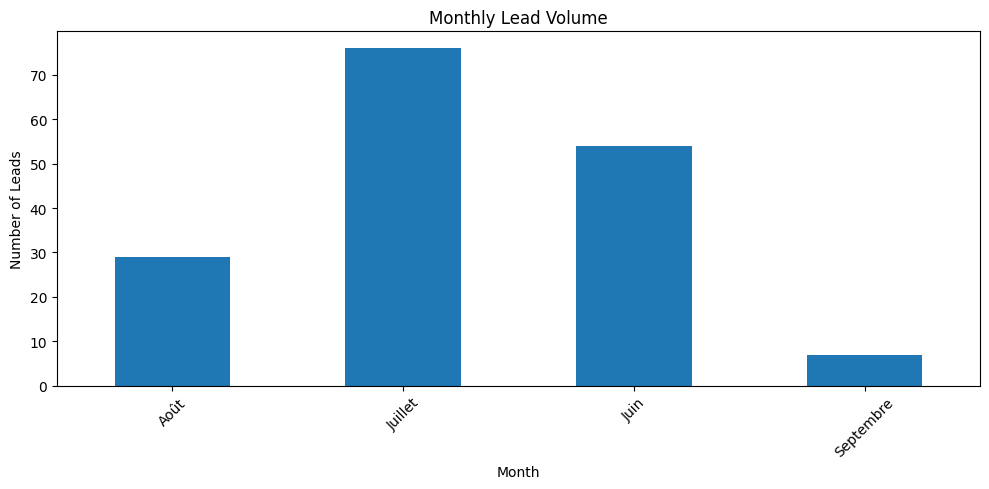

In [27]:
import matplotlib.pyplot as plt

monthly_leads["Lead Count"].plot(
    kind="bar",
    figsize=(10, 5),
    title="Monthly Lead Volume"
)

plt.xlabel("Month")
plt.ylabel("Number of Leads")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [28]:
source_analysis = (
    anon_df["Source du lead"]
    .fillna("Missing")
    .value_counts()
    .to_frame("Lead Count")
)

source_analysis["Share (%)"] = (
    source_analysis["Lead Count"] / len(anon_df) * 100
).round(2)

display(source_analysis)

,Lead Count,Share (%)
Source du lead,,
Messenger,63,37.95
WhatsApp,53,31.93
Instagram,26,15.66
Missing,17,10.24
Appel direct,7,4.22


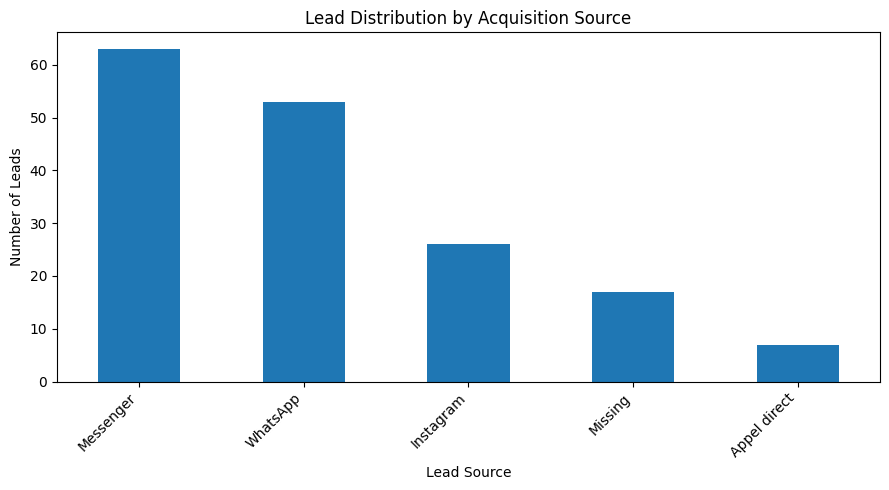

In [29]:
source_analysis["Lead Count"].plot(
    kind="bar",
    figsize=(9, 5),
    title="Lead Distribution by Acquisition Source"
)

plt.xlabel("Lead Source")
plt.ylabel("Number of Leads")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [30]:
service_analysis = (
    anon_df["Service Standardized"]
    .fillna("Missing")
    .value_counts()
    .to_frame("Lead Count")
)

service_analysis["Share (%)"] = (
    service_analysis["Lead Count"] / len(anon_df) * 100
).round(2)

display(service_analysis.head(15))

,Lead Count,Share (%)
Service Standardized,,
Fonctions cachées,42,25.3
Navigation GPS,23,13.86
Apple CarPlay,21,12.65
Missing,20,12.05
Navigation + Apple CarPlay,6,3.61
Navigation,6,3.61
Navigation + Android Auto,5,3.01
Activation alarme,4,2.41
Autre,4,2.41


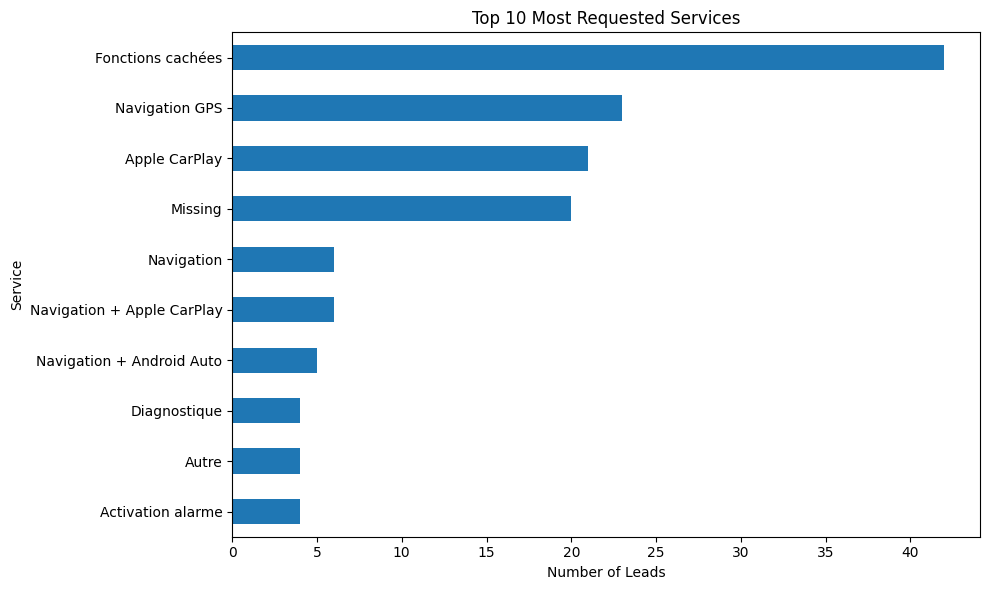

In [31]:
service_analysis["Lead Count"].head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Most Requested Services"
)

plt.xlabel("Number of Leads")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

In [32]:
status_analysis = (
    anon_df["Status Group"]
    .fillna("Unclassified")
    .value_counts()
    .to_frame("Lead Count")
)

status_analysis["Share (%)"] = (
    status_analysis["Lead Count"] / len(anon_df) * 100
).round(2)

display(status_analysis)

,Lead Count,Share (%)
Status Group,,
In progress,62,37.35
Appointment confirmed,54,32.53
Service completed,23,13.86
Unclassified,10,6.02
Not feasible,7,4.22
Cancelled,7,4.22
Needs review,2,1.20
Appointment attended - completion unverified,1,0.60


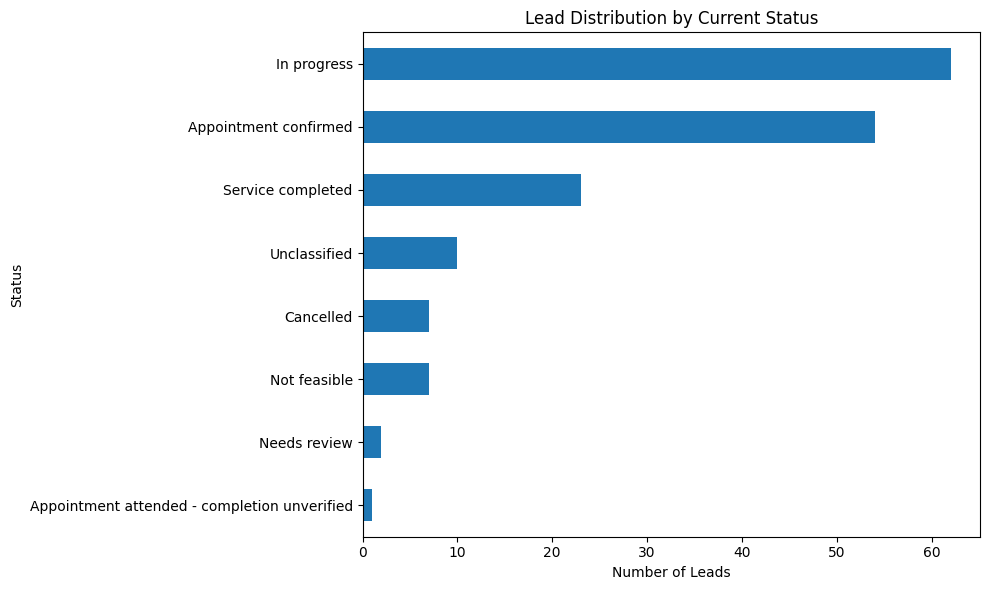

In [33]:
status_analysis["Lead Count"].sort_values().plot(
    kind="barh",
    figsize=(10, 6),
    title="Lead Distribution by Current Status"
)

plt.xlabel("Number of Leads")
plt.ylabel("Status")
plt.tight_layout()
plt.show()

In [34]:
source_completion = (
    anon_df.assign(
        Completed=anon_df["Status Group"].eq("Service completed")
    )
    .groupby("Source du lead", dropna=False)
    .agg(
        Total_Leads=("Lead ID", "count"),
        Completed_Leads=("Completed", "sum")
    )
)

source_completion["Completion Rate (%)"] = (
    source_completion["Completed_Leads"]
    / source_completion["Total_Leads"] * 100
).round(2)

display(
    source_completion.sort_values(
        "Completed_Leads", ascending=False
    )
)

,Total_Leads,Completed_Leads,Completion Rate (%)
Source du lead,,,
WhatsApp,53,19,35.85
Instagram,26,2,7.69
Messenger,63,1,1.59
<NA>,17,1,5.88
Appel direct,7,0,0.00


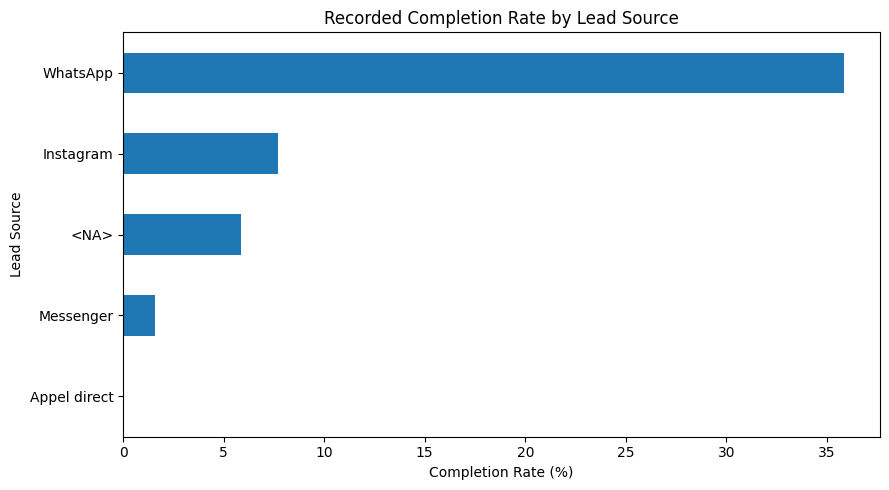

In [35]:
source_completion["Completion Rate (%)"].sort_values().plot(
    kind="barh",
    figsize=(9, 5),
    title="Recorded Completion Rate by Lead Source"
)

plt.xlabel("Completion Rate (%)")
plt.ylabel("Lead Source")
plt.tight_layout()
plt.show()

In [36]:
service_completion = (
    anon_df.assign(
        Completed=anon_df["Status Group"].eq("Service completed")
    )
    .groupby("Service Standardized", dropna=False)
    .agg(
        Total_Leads=("Lead ID", "count"),
        Completed_Leads=("Completed", "sum")
    )
)

service_completion["Completion Rate (%)"] = (
    service_completion["Completed_Leads"]
    / service_completion["Total_Leads"] * 100
).round(2)

display(
    service_completion
    .sort_values("Completed_Leads", ascending=False)
    .head(15)
)

,Total_Leads,Completed_Leads,Completion Rate (%)
Service Standardized,,,
Fonctions cachées,42,6,14.29
Navigation GPS,23,3,13.04
Activation alarme,4,2,50.00
Diagnostique,4,2,50.00
Alarme,1,1,100.00
"Alarme, Wireless CarPlay+ Camera recul",1,1,100.00
GPS,1,1,100.00
Navigation,6,1,16.67
Navigation + android auto + My BMW,1,1,100.00


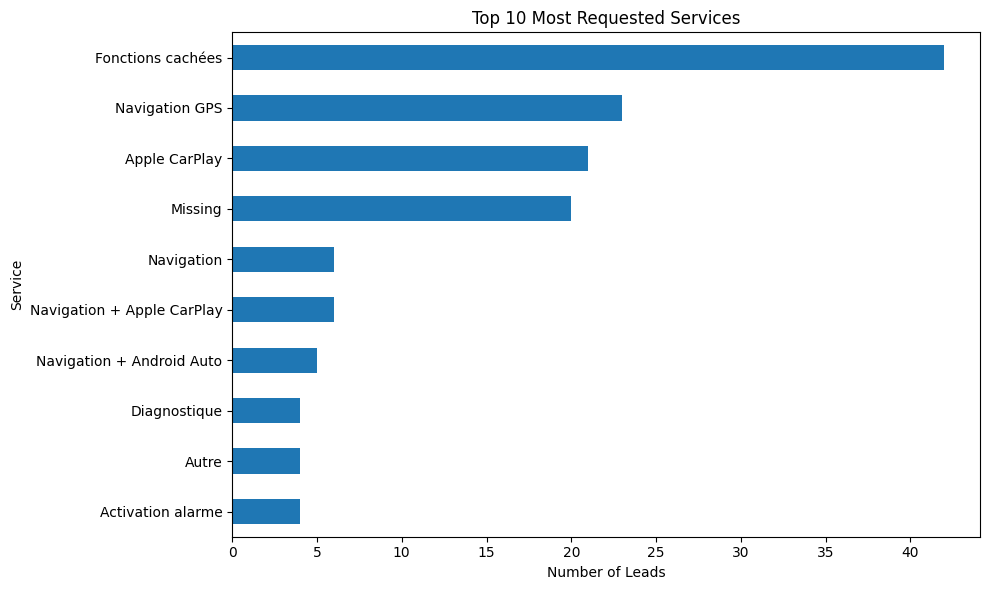

In [37]:
top_services = (
    anon_df["Service Standardized"]
    .fillna("Missing")
    .value_counts()
    .head(10)
    .sort_values()
)

top_services.plot(
    kind="barh",
    figsize=(10, 6),
    title="Top 10 Most Requested Services"
)

plt.xlabel("Number of Leads")
plt.ylabel("Service")
plt.tight_layout()
plt.show()

In [38]:
print(anon_df.columns.tolist())

['Lead ID', 'Source du lead', 'Gouvernorat', 'Modèle véhicule', 'Service demandé', 'Modèle de poste', 'Date RDV', 'Statut', 'Confirm. J-1', 'Lead Month', 'Source Sheet', 'Status Group', 'Service Standardized']


In [41]:
sql_column_mapping = {
    "Lead ID": "lead_id",
    "Source du lead": "source_du_lead",
    "Gouvernorat": "gouvernorat",
    "Modèle véhicule": "modele_vehicule",
    "Service demandé": "service_demande",
    "Modèle de poste": "modele_de_poste",
    "Date RDV": "date_rdv",
    "Statut": "statut",
    "Confirm. J-1": "confirm_j1",
    "Lead Month": "lead_month",
    "Source Sheet": "source_sheet",
    "Status Group": "status_group",
    "Service Standardized": "service_standardized"
}

sql_df = anon_df.rename(columns=sql_column_mapping)

print(sql_df.shape)
print(sql_df.columns.tolist())
display(sql_df.head())

(166, 13)
['lead_id', 'source_du_lead', 'gouvernorat', 'modele_vehicule', 'service_demande', 'modele_de_poste', 'date_rdv', 'statut', 'confirm_j1', 'lead_month', 'source_sheet', 'status_group', 'service_standardized']


,lead_id,source_du_lead,gouvernorat,modele_vehicule,service_demande,modele_de_poste,date_rdv,statut,confirm_j1,lead_month,source_sheet,status_group,service_standardized
0,LEAD_001,Messenger,NaN,Mercedes CLA,Fonctions cachées,NaN,NaN,Nouveau lead,NaN,Juin,📅 Juin,In progress,Fonctions cachées
1,LEAD_002,Instagram,NaN,VW Golf 7.5,Apple CarPlay,MST2_EU_VW_ZR_P0475T,NaN,Nouveau lead,NaN,Juin,📅 Juin,In progress,Apple CarPlay
2,LEAD_003,Instagram,NaN,SEAT leon,Fonctions cachées,5F0035824C,NaN,Nouveau lead,NaN,Juin,📅 Juin,In progress,Fonctions cachées
3,LEAD_004,Messenger,NaN,Mercedes Classe C,Activation alarme,NaN,NaN,Nouveau lead,NaN,Juin,📅 Juin,In progress,Activation alarme
4,LEAD_005,Messenger,NaN,Mercedes GLC,Fonctions cachées,NaN,NaN,Nouveau lead,NaN,Juin,📅 Juin,In progress,Fonctions cachées


In [42]:
print("Rows:", len(sql_df))
print("Columns:", len(sql_df.columns))

sql_df.to_csv(
    "../data/processed/leads_sql_ready.csv",
    index=False,
    encoding="utf-8-sig"
)

print("SQL-ready CSV saved successfully.")

Rows: 166
Columns: 13
SQL-ready CSV saved successfully.
